---
## 17.1 წრფივი კლასიფიკატორის გაწვრთნა (Training a Linear Classifier)
*PDF გვ. 282–285 (წიგნის გვ. 267–269)*

**ამოცანა (Problem):** გსურთ გაწვრთნათ მოდელი დაკვირვებების (ობიექტების) კლასიფიკაციისთვის.  
**გადაწყვეტა (Solution):** გამოიყენეთ საყრდენი ვექტორების კლასიფიკატორი (`LinearSVC`), რომელიც პოულობს კლასებს შორის მაქსიმალური მინდვრის (margin) მქონე ჰიპერსიბრტყეს.

In [33]:
# Load libraries
from sklearn.svm import LinearSVC
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
import numpy as np

# Load data with only two classes and two features
iris = datasets.load_iris()
features = iris.data[:100,:2]
target = iris.target[:100]

# Standardize features
scaler = StandardScaler()
features_standardized = scaler.fit_transform(features)

# Create support vector classifier
svc = LinearSVC(C=1000)

# Train model
model = svc.fit(features_standardized, target)

### 17.1 Discussion — ჰიპერსიბრტყის (გამყოფი წრფის) და „გზის კიდეების“ (Margins) ვიზუალიზაცია 2D სივრცეში
დავხატოთ სტანდარტიზებული მონაცემთა წერტილები (წითელი და ლურჯი ფერებით), კოორდინატთა სიბრტყე, `LinearSVC`-ის მიერ ნაპოვნი მთავარი გამყოფი წრფე ($\mathbf{w}\cdot\mathbf{x} + b = 0$) და წყვეტილი ხაზებით — „გზის კიდეები“ / ბორდიურები ($\mathbf{w}\cdot\mathbf{x} + b = \pm 1$):

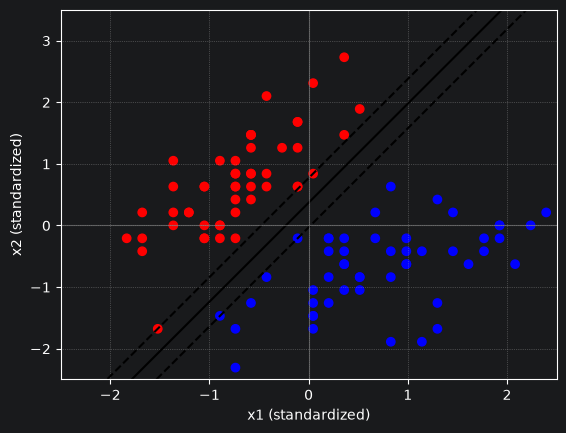

In [34]:
# Load library
from matplotlib import pyplot as plt

# Plot data points and color using their class (red = class 0, blue = class 1)
color = ["red" if c == 0 else "blue" for c in target]
plt.scatter(features_standardized[:,0], features_standardized[:,1], c=color)

# Create the hyperplane (w*x + b = 0)
w = svc.coef_[0]
a = -w[0] / w[1]
xx = np.linspace(-2.5, 2.5)
yy = a * xx - (svc.intercept_[0]) / w[1]

# Create the margin lines ("road edges": w*x + b = -1 and +1)
yy_down = yy - 1 / w[1]
yy_up = yy + 1 / w[1]

# Plot the hyperplane and dashed margin lines
plt.plot(xx, yy, "k-")
plt.plot(xx, yy_down, "k--")
plt.plot(xx, yy_up, "k--")

# Show coordinate axes and grid so (-2, 3) position is clearly visible
plt.axhline(0, color="grey", linewidth=0.8, alpha=0.6)
plt.axvline(0, color="grey", linewidth=0.8, alpha=0.6)
plt.xlim(-2.5, 2.5)
plt.ylim(-2.5, 3.5)
plt.xlabel("x1 (standardized)")
plt.ylabel("x2 (standardized)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show();

### 17.1 Discussion — ახალი დაკვირვების პროგნოზირება
წრფის მარცხნივ/ზემოთ მდებარე ყველა წერტილი მიეკუთვნება კლასს `0` (**წითელი**), ხოლო მარჯვნივ/ქვემოთ — კლასს `1` (**ლურჯი**). შევამოწმოთ ახალი წერტილით `[-2, 3]`:

In [35]:
# Create new observation
new_observation = [[ -2,  3]]

# Predict class of new observation
"წითელი" if svc.predict(new_observation)[0] == 0 else "ლურჯი"

'წითელი'

---
## 17.2 წრფივად განუყოფელი კლასების დამუშავება ბირთვების გამოყენებით (Handling Linearly Inseparable Classes Using Kernels)
*PDF გვ. 285–289 (წიგნის გვ. 270–274)*

**ამოცანა (Problem):** გსურთ გაწვრთნათ Support Vector Classifier, მაგრამ კლასები წრფივად განუყოფელია (linearly inseparable).  
**გადაწყვეტა (Solution):** გამოიყენეთ ბირთვის ფუნქციები (`kernel="rbf"`) არაწრფივი გადაწყვეტილების საზღვრების შესაქმნელად.

In [36]:
# Load libraries
from sklearn.svm import SVC
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
import numpy as np

# Set randomization seed
np.random.seed(0)

# Generate two features
features = np.random.randn(200, 2)

# Use a XOR gate (you don't need to know what this is) to generate
# linearly inseparable classes
target_xor = np.logical_xor(features[:, 0] > 0, features[:, 1] > 0)
target = np.where(target_xor, 0, 1)

# Create a support vector machine with a radial basis function kernel
svc = SVC(kernel="rbf", random_state=0, gamma=1, C=1)

# Train the classifier
model = svc.fit(features, target)

### 17.2 Discussion — გადაწყვეტილების არეების და „გზის კიდეების“ დახატვის ფუნქცია (`plot_decision_regions`)
დამხმარე ფუნქცია (Sebastian Raschka-ს მიხედვით), რომელიც 2D სივრცეში ხატავს დაკვირვებებს, გადაწყვეტილების საზღვარს (მთლიანი ხაზი: `0`) და „გზის კიდეებს“ (წყვეტილი ხაზები: `-1` და `+1` `decision_function`-ით):

In [37]:
# Plot observations and decision boundary hyperplane
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt

def plot_decision_regions(X, y, classifier):
    cmap = ListedColormap(("red", "blue"))
    xx1, xx2 = np.meshgrid(np.arange(-3, 3, 0.02), np.arange(-3, 3, 0.02))
    grid = np.array([xx1.ravel(), xx2.ravel()]).T
    Z = classifier.predict(grid)
    Z = Z.reshape(xx1.shape)
    plt.contourf(xx1, xx2, Z, alpha=0.1, cmap=cmap)

    # Plot main boundary (0, solid) and margin "road edges" (-1 and +1, dashed)
    if hasattr(classifier, "decision_function"):
        Z_dec = classifier.decision_function(grid).reshape(xx1.shape)
        plt.contour(xx1, xx2, Z_dec, levels=[-1, 0, 1], colors="k",
                    linestyles=["--", "-", "--"], alpha=0.7)

    for idx, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y == cl, 0], y=X[y == cl, 1],
                    alpha=0.8, color=cmap(idx),
                    marker="+", label=cl)

### 17.2 Discussion — ნაბიჯი 1: წრფივი ბირთვი (`kernel="linear"`) XOR მონაცემებზე
ჯერ გავწვრთნათ `SVC` წრფივი ბირთვით და ვნახოთ, როგორ მარცხდება სწორი წრფე XOR-ის არაწრფივ კლასებზე:

In [38]:
# Create support vector classifier with a linear kernel
svc_linear = SVC(kernel="linear", random_state=0, C=1)

# Train model
svc_linear.fit(features, target)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


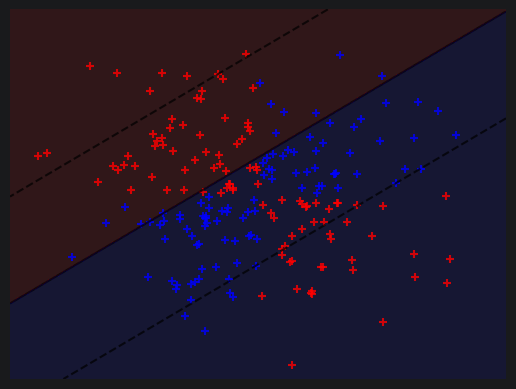

In [39]:
# Plot observations and hyperplane
plot_decision_regions(features, target, classifier=svc_linear)
plt.axis("off"), plt.show();

### 17.2 Discussion — ნაბიჯი 2: RBF ბირთვი (`kernel="rbf"`) XOR მონაცემებზე
ახლა შევცვალოთ წრფივი ბირთვი რადიალური საბაზისო ფუნქციის ბირთვით (`kernel="rbf"`) და დავხატოთ არაწრფივი გადაწყვეტილების საზღვარი:

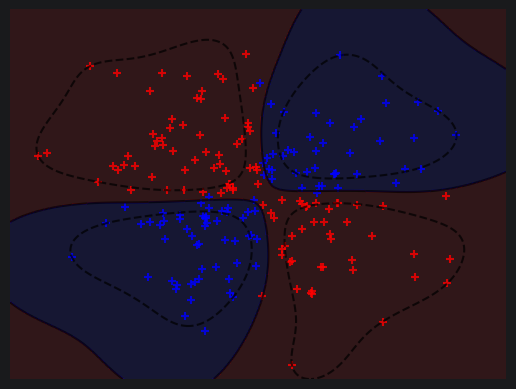

In [42]:
# Create a support vector machine with a radial basis function kernel
svc = SVC(kernel="rbf", random_state=0, gamma=1, C=1)

# Train the classifier
model = svc.fit(features, target)

# Plot observations and hyperplane
plot_decision_regions(features, target, classifier=svc)
plt.axis("off"), plt.show();